In his 1935 *Psycho-Biology of Language*, George Zipf studied the relationship between how often a word appears and how long it tends to be. Working with four plays of Plautus, he showed that frequently used words tend to be shorter—a pattern now known as [Zipf's law of abbreviation](https://en.wikipedia.org/wiki/Zipf%27s_law). The more often a word is used, the fewer syllables it has on average.

Can we replicate his result? Using the same four plays from the [Tesserae](https://tesserae.caset.buffalo.edu/) corpus, we count word frequencies, estimate syllable counts, and plot the relationship on a log-log scale—following Zipf's original method.

**NB**: This is an updated version of a [blog post](https://disiectamembra.wordpress.com/2017/04/09/replicating-zipf/) I originally wrote in April 2017. The original used raw Tesserae text files with manual preprocessing; the code below streamlines the loading but keeps the same approach.

## Setup

In [1]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Loading the texts

Zipf used four plays of Plautus: *Aulularia*, *Mostellaria*, *Pseudolus*, and *Trinummus*. The Tesserae corpus has all twenty extant Plautus plays, but we use the same four for direct comparison with Zipf's results.

In [2]:
tess_dir = Path.home() / 'latincy_data' / 'lat_text_tesserae' / 'texts'

plautus_files = [
    'plautus.aulularia.tess',
    'plautus.mostellaria.tess',
    'plautus.pseudolus.tess',
    'plautus.trinummus.tess',
]

# Load and tokenize: strip Tesserae citation tags, extract alphabetic tokens
tokens = []
for filename in plautus_files:
    text = (tess_dir / filename).read_text()
    text = re.sub(r'<.+?>\s*', '', text)  # strip citation tags
    tokens.extend(re.findall(r'[a-zA-Z]+', text.lower()))

print(f'{len(tokens):,} tokens from {len(plautus_files)} plays')
print(f'{len(set(tokens)):,} unique word types')

35,188 tokens from 4 plays
8,464 unique word types


## Estimating syllable counts

Latin syllable counting is not trivial—there are rules for diphthongs, *qu* clusters, and vowel hiatus. As a rough approximation, we count vowels per word, collapsing common diphthongs (*ae*, *oe*, *ei*) and treating *qu* as a single consonant. This follows the same heuristic used in the original notebook.

In [3]:
def syll_count(word):
    """Estimate syllable count by counting vowels after collapsing diphthongs."""
    word = word.replace('qu', 'qv')
    word = word.replace('ae', 'e')
    word = word.replace('oe', 'e')
    word = word.replace('ei', 'e')
    return sum(c in 'aeiouy' for c in word)

## Building the frequency table

For each unique word, we record its frequency (how many times it appears) and its estimated syllable count. We then group by frequency and compute the average syllable count for each frequency level—exactly as Zipf did.

In [4]:
counts = Counter(tokens)
data = [(word, syll_count(word), freq) for word, freq in counts.items()]

df = pd.DataFrame(data, columns=['word', 'syllables', 'count'])
df.head()

,word,syllables,count
0,ne,1,185
1,quis,1,63
2,miretur,3,1
3,qui,1,301
4,sim,1,18


In [5]:
# Group by frequency: how many words appear N times, and their average syllable count
grouped = df.groupby('count').agg(
    words=('count', 'size'),
    avg_syll=('syllables', 'mean')
).reset_index().rename(columns={'count': 'occurrences'})

grouped.head(10)

,occurrences,words,avg_syll
0,1,5448,3.282122
1,2,1195,2.947280
2,3,492,2.788618
3,4,301,2.714286
4,5,152,2.631579
5,6,137,2.598540
6,7,84,2.440476
7,8,73,2.438356
8,9,51,2.411765
9,10,44,2.431818


## Comparing with Zipf's results

Zipf reported 33,094 tokens and an average syllable count of 3.23 for words appearing exactly once (*hapax legomena*). How do our numbers compare?

In [6]:
hapax_syll = grouped.loc[grouped['occurrences'] == 1, 'avg_syll'].values[0]
dis_syll = grouped.loc[grouped['occurrences'] == 2, 'avg_syll'].values[0]

print(f'Total tokens: {len(tokens):,} (Zipf: 33,094)')
print(f'Hapax avg syllables: {hapax_syll:.2f} (Zipf: 3.23)')
print(f'Dis legomena avg syllables: {dis_syll:.2f} (Zipf: 2.92)')

Total tokens: 35,188 (Zipf: 33,094)
Hapax avg syllables: 3.28 (Zipf: 3.23)
Dis legomena avg syllables: 2.95 (Zipf: 2.92)


## Plotting the result

On a double logarithmic scale, the relationship between the number of words at each frequency level and their frequency of occurrence should approximate a straight line—the signature of a power law.

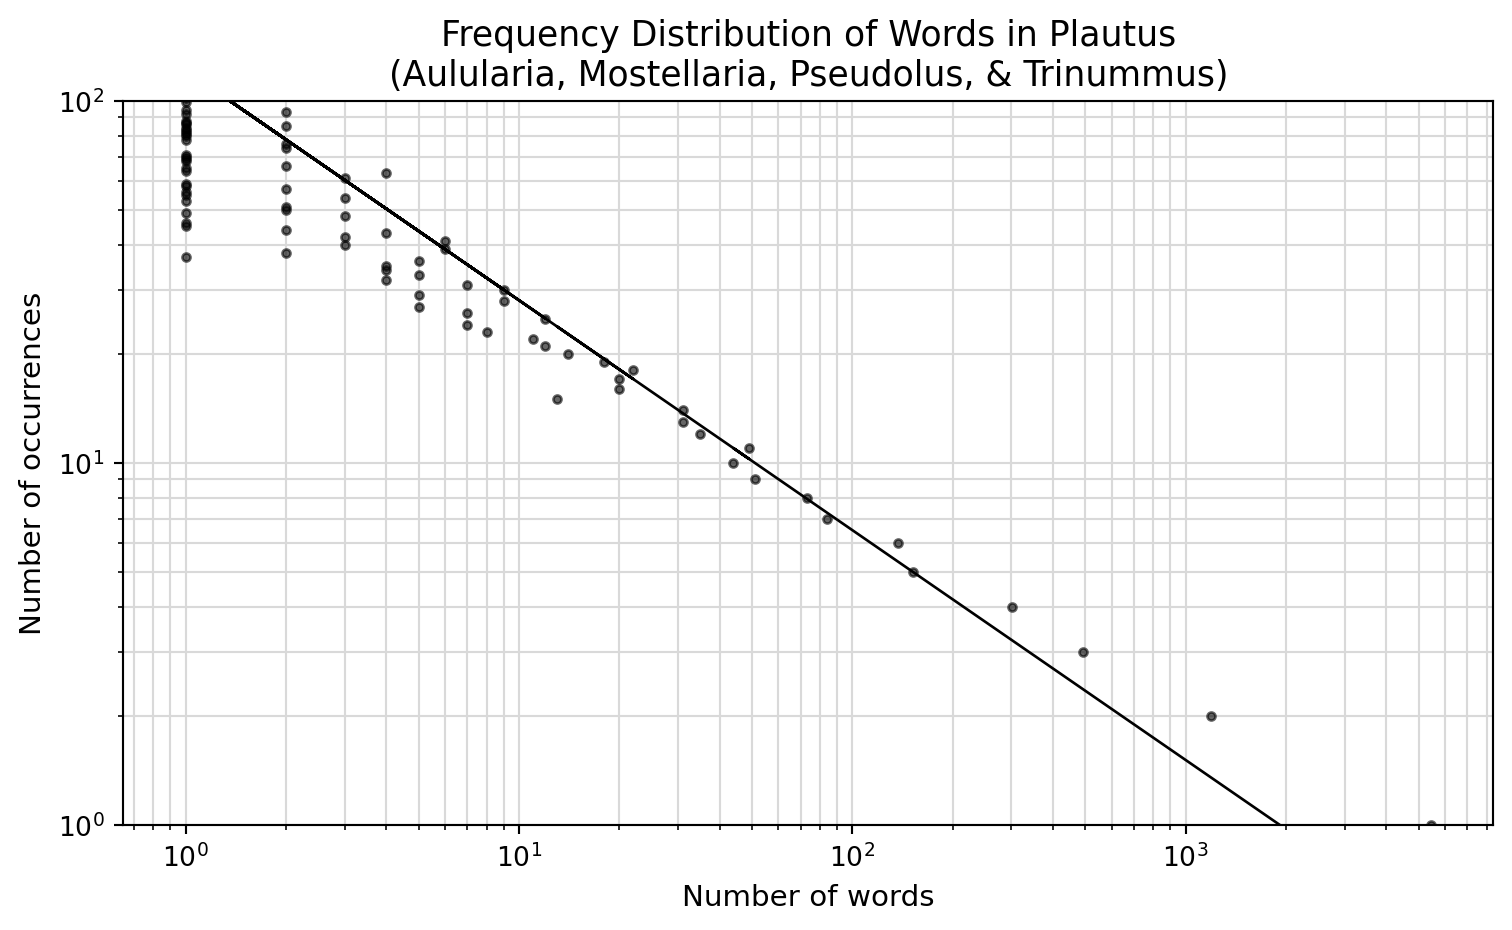

Slope: -0.635


In [7]:
x = grouped['words']
y = grouped['occurrences']

# Fit a line in log-log space
logx = np.log(x)
logy = np.log(y)
coeffs = np.polyfit(logx, logy, deg=1)
poly = np.poly1d(coeffs)
yfit = lambda x: np.exp(poly(np.log(x)))

fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(x, y, 'o', color='black', markersize=3, alpha=0.6)
ax.loglog(x, yfit(x), color='black', linewidth=1)

ax.set_title('Frequency Distribution of Words in Plautus\n'
             '(Aulularia, Mostellaria, Pseudolus, & Trinummus)',
             fontsize=13)
ax.set_xlabel('Number of words', fontsize=11)
ax.set_ylabel('Number of occurrences', fontsize=11)
ax.set_ylim(1, 100)
ax.grid(True, which='both', ls='-', color='0.85')

plt.tight_layout()
plt.show()

print(f'Slope: {coeffs[0]:.3f}')

## Discussion

The replication closely matches Zipf's original 1935 results. The inverse relationship between word frequency and syllable count holds: the most common words in Plautus (*et*, *est*, *non*, *ut*) are short, while rare words tend to be longer.

A few notes:

- **Token counts differ slightly** from Zipf's 33,094. This likely reflects differences in text editions and tokenization conventions.
- **The syllable heuristic is approximate.** A proper Latin syllabifier would handle cases like vowel hiatus and consonant clusters more accurately, but the vowel-counting method is sufficient to reproduce the overall pattern.
- **Zipf's method is not Zipf's *law*.** The rank-frequency distribution (rank × frequency ≈ constant) is the more famous result. What we replicate here is the frequency-abbreviation relationship: a distinct but related finding from the same 1935 study.

<hr>

<p><em>Originally written April 9, 2017. Updated April 2026.</em></p>